# Project 3 · AI-Powered Attendance System

**Assignment:** a camera **scans the classroom** at the start of a lecture, **recognises students' faces** against a pre-registered database, and **marks attendance automatically in a CSV/DB file**.
**Tech stack:** OpenCV, Python, a face-recognition model, **Pandas/SQLite** for attendance logs.
**Deliverables checklist:**
- [ ] prototype with **at least 10 registered students** (Sections 3–4)
- [ ] **attendance log file generated automatically** (Section 6 writes the CSV and the database)
- [ ] **evaluation of accuracy and limitations** (Sections 7–8)

> This notebook ran once in **demo mode** on public sample photos. For your submission, put your students' photos in `data/students/`, your classroom photos or video in `data/class/`, set `DEMO = False`, and run it again.

### How it differs from Project 1 (security gate)
| | Security gate | Attendance |
|---|---|---|
| Faces per frame | one person at the door | **many** students at once |
| Decision | allow / reject **now** | mark **present once per session**; everyone else is **absent** |
| Output | live green/red message + access log | an **attendance sheet** (CSV + database) |
| Main risk | letting a stranger in | marking an absent student present (proxy attendance) or missing someone at the back |

The recognition core is the same: **YuNet** finds faces, **SFace** turns each face into a 128-number embedding, and **cosine similarity** decides who it is.

## 0 · Setup
```
pip install opencv-python numpy pandas matplotlib
```
```
project/
├── project3_attendance_system.ipynb
├── models/                               ← downloaded automatically (shared with project 1)
├── data/students/<RollNo>_<Name>/*.jpg   ← 3-5 photos per student (10+ students)
├── data/class/*.jpg  (or *.mp4)          ← classroom snapshots or a short video
├── data/class/present.txt                ← (for evaluation) roll numbers that were really present
├── attendance.db                         ← SQLite database
└── attendance_logs/                      ← one CSV per session
```

In [1]:
%matplotlib inline
import os, glob, sqlite3, datetime, urllib.request
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
cv2.utils.logging.setLogLevel(cv2.utils.logging.LOG_LEVEL_ERROR)

DEMO = True
THRESHOLD = 0.363          # cosine similarity needed to count as a match
DB_PATH = "demo_attendance.db" if DEMO else "attendance.db"
if DEMO and os.path.exists(DB_PATH):
    os.remove(DB_PATH)     # start the demo from a clean database every run
for d in ["models", "data/students", "data/class", "attendance_logs"]:
    os.makedirs(d, exist_ok=True)

MODELS = {
    "models/face_detection_yunet_2023mar.onnx":
        "https://media.githubusercontent.com/media/opencv/opencv_zoo/main/models/face_detection_yunet/face_detection_yunet_2023mar.onnx",
    "models/face_recognition_sface_2021dec.onnx":
        "https://media.githubusercontent.com/media/opencv/opencv_zoo/main/models/face_recognition_sface/face_recognition_sface_2021dec.onnx",
}
for path, url in MODELS.items():
    if not os.path.exists(path) or os.path.getsize(path) < 100_000:
        print("downloading", os.path.basename(path)); urllib.request.urlretrieve(url, path)
print("models ready | OpenCV", cv2.__version__, "| demo mode:", DEMO)

models ready | OpenCV 5.0.0 | demo mode: True


## 1 · Face engine (same as Project 1)
`min_face` matters even more here: students at the **back of the room** appear small. Faces narrower than `min_face` pixels are skipped rather than guessed, because a wrong guess marks the wrong student. Use a high-resolution camera, or several snapshots from the front.

In [2]:
class FaceEngine:
    """Detect faces (YuNet) and turn each face into a 128-number 'faceprint' (SFace)."""

    def __init__(self, detector_path, recognizer_path, min_face=60, score_threshold=0.8):
        self.detector = cv2.FaceDetectorYN.create(detector_path, "", (320, 320), score_threshold, 0.3, 5000)
        self.recognizer = cv2.FaceRecognizerSF.create(recognizer_path, "")
        self.min_face = min_face          # ignore faces narrower than this (too small to recognise reliably)

    def detect(self, image):
        """Return an array of faces; each row = [x, y, w, h, 5 landmark points (10 numbers), score]."""
        h, w = image.shape[:2]
        self.detector.setInputSize((w, h))
        _, faces = self.detector.detect(image)
        if faces is None:
            return np.zeros((0, 15), np.float32)
        return faces[faces[:, 2] >= self.min_face]

    def embed(self, image, face):
        """Align the face using its landmarks, then compute a unit-length 128-d embedding."""
        aligned = self.recognizer.alignCrop(image, face)
        vec = self.recognizer.feature(aligned).flatten().astype(np.float32)
        return vec / np.linalg.norm(vec)

    def largest_face(self, image):
        faces = self.detect(image)
        if len(faces) == 0:
            return None
        return faces[np.argmax(faces[:, 2] * faces[:, 3])]

engine = FaceEngine("models/face_detection_yunet_2023mar.onnx", "models/face_recognition_sface_2021dec.onnx", min_face=60)
print("engine ready")

engine ready


### Demo data (only when `DEMO = True`)
Six demo students are registered from public sample portraits (sources printed below). The "classroom camera" takes **three snapshots**: two real two-person photos (one taken on a different day from the students' registration photos) and a street photo with strangers whose faces are too small to use. Students 103 and 104 are **absent**.

In [3]:
SOURCES = {
    "obama.jpg": "https://raw.githubusercontent.com/ageitgey/face_recognition/master/examples/obama.jpg",
    "biden.jpg": "https://raw.githubusercontent.com/ageitgey/face_recognition/master/examples/biden.jpg",
    "two_people.jpg": "https://raw.githubusercontent.com/ageitgey/face_recognition/master/examples/two_people.jpg",
    "lena.jpg": "https://raw.githubusercontent.com/opencv/opencv/4.x/samples/data/lena.jpg",
    "grace_hopper.jpg": "https://raw.githubusercontent.com/matplotlib/matplotlib/main/lib/matplotlib/mpl-data/sample_data/grace_hopper.jpg",
    "zidane.jpg": "https://github.com/ultralytics/assets/releases/download/v0.0.0/zidane.jpg",
    "bus.jpg": "https://github.com/ultralytics/assets/releases/download/v0.0.0/bus.jpg",
}

def augment(img, kind):
    if kind == "bright": return cv2.convertScaleAbs(img, alpha=1.2, beta=35)
    if kind == "dark":   return cv2.convertScaleAbs(img, alpha=0.6, beta=0)
    if kind == "mirror": return cv2.flip(img, 1)
    if kind == "rotate":
        h, w = img.shape[:2]
        return cv2.warpAffine(img, cv2.getRotationMatrix2D((w / 2, h / 2), 10, 1.0), (w, h), borderMode=cv2.BORDER_REFLECT)
    return img

def face_crops(img, pad=0.5, out=320):
    faces = engine.detect(img)
    crops = []
    for f in faces[np.argsort(-faces[:, 2])]:
        x, y, w, h = f[:4]; cx, cy = x + w / 2, y + h / 2; s = max(w, h) * (1 + pad)
        crops.append(cv2.resize(img[int(max(cy - s / 2, 0)):int(cy + s / 2), int(max(cx - s / 2, 0)):int(cx + s / 2)], (out, out)))
    return crops

def build_demo(root="demo_class_data"):
    if os.path.exists(os.path.join(root, "done.txt")):
        return root
    src = os.path.join(root, "source"); os.makedirs(src, exist_ok=True)
    for n, u in SOURCES.items():
        if not os.path.exists(os.path.join(src, n)):
            urllib.request.urlretrieve(u, os.path.join(src, n))
    load = lambda n: cv2.imread(os.path.join(src, n))
    zid = face_crops(load("zidane.jpg"))
    students = {"101_StudentA": load("obama.jpg"), "102_StudentB": load("biden.jpg"), "103_StudentC": load("lena.jpg"),
                "104_StudentD": load("grace_hopper.jpg"), "105_StudentE": zid[0], "106_StudentF": zid[1]}
    for sid, img in students.items():
        d = os.path.join(root, "students", sid); os.makedirs(d, exist_ok=True)
        for kind in ["none", "bright", "rotate"]:
            cv2.imwrite(os.path.join(d, f"{kind}.jpg"), augment(img, kind))
    cls = os.path.join(root, "class"); os.makedirs(cls, exist_ok=True)
    cv2.imwrite(os.path.join(cls, "snapshot_1.jpg"), load("two_people.jpg"))                     # 101 + 102, a different day
    cv2.imwrite(os.path.join(cls, "snapshot_2.jpg"), augment(load("zidane.jpg"), "dark"))        # 105 + 106, darker light
    cv2.imwrite(os.path.join(cls, "snapshot_3.jpg"), load("bus.jpg"))                            # strangers, small faces
    open(os.path.join(cls, "present.txt"), "w").write("101\n102\n105\n106\n")
    open(os.path.join(root, "done.txt"), "w").write("ok")
    return root

DATA = build_demo() if DEMO else "data"
print("data folder:", DATA)
print("students:", sorted(os.listdir(os.path.join(DATA, "students"))))
print("class snapshots:", sorted(f for f in os.listdir(os.path.join(DATA, "class")) if not f.endswith(".txt")))

data folder: demo_class_data
students: ['101_StudentA', '102_StudentB', '103_StudentC', '104_StudentD', '105_StudentE', '106_StudentF']
class snapshots: ['snapshot_1.jpg', 'snapshot_2.jpg', 'snapshot_3.jpg']


## 2 · Database: students, faceprints, sessions, attendance

In [4]:
def connect(path=DB_PATH):
    con = sqlite3.connect(path)
    con.executescript('''
        CREATE TABLE IF NOT EXISTS students (roll_no TEXT PRIMARY KEY, name TEXT NOT NULL, registered_at TEXT);
        CREATE TABLE IF NOT EXISTS embeddings (id INTEGER PRIMARY KEY AUTOINCREMENT,
            roll_no TEXT NOT NULL REFERENCES students(roll_no), vector BLOB NOT NULL);
        CREATE TABLE IF NOT EXISTS sessions (id INTEGER PRIMARY KEY AUTOINCREMENT, course TEXT, started_at TEXT);
        CREATE TABLE IF NOT EXISTS attendance (session_id INTEGER REFERENCES sessions(id), roll_no TEXT,
            status TEXT, first_seen TEXT, score REAL, PRIMARY KEY (session_id, roll_no));
    ''')
    return con

def register_students(con, students_dir):
    rows = []
    for folder in sorted(glob.glob(os.path.join(students_dir, "*"))):
        roll_no, _, name = os.path.basename(folder).partition("_")
        vecs = []
        for path in sorted(glob.glob(os.path.join(folder, "*"))):
            img = cv2.imread(path)
            face = engine.largest_face(img) if img is not None else None
            if face is not None:
                vecs.append(engine.embed(img, face))
        con.execute("INSERT OR REPLACE INTO students VALUES (?, ?, ?)",
                    (roll_no, name, datetime.datetime.now().isoformat(timespec="seconds")))
        con.execute("DELETE FROM embeddings WHERE roll_no = ?", (roll_no,))
        con.executemany("INSERT INTO embeddings(roll_no, vector) VALUES (?, ?)", [(roll_no, v.tobytes()) for v in vecs])
        rows.append((roll_no, name, len(vecs)))
    con.commit()
    return pd.DataFrame(rows, columns=["roll_no", "name", "photos used"])

con = connect()
print(register_students(con, os.path.join(DATA, "students")).to_string(index=False))
n = con.execute("SELECT COUNT(*) FROM students").fetchone()[0]
print(f"\n{n} students registered" + ("" if n >= 10 else "  (the assignment needs at least 10 - add more for your submission)"))

roll_no     name  photos used
    101 StudentA            3
    102 StudentB            3
    103 StudentC            3
    104 StudentD            3
    105 StudentE            3
    106 StudentF            3

6 students registered  (the assignment needs at least 10 - add more for your submission)


## 3 · Recognising every face in a classroom frame

Three rules make attendance robust:
1. **Each face is matched to its best student** if the similarity passes the threshold, otherwise "unknown".
2. **One face can't be two students, and one student can't be claimed by two faces in the same frame.** We assign greedily, best score first.
3. Over the whole session we keep each student's **best** score and **first-seen time**, so taking several snapshots or video frames only helps.

In [5]:
def load_gallery(con):
    rows = con.execute("SELECT roll_no, vector FROM embeddings").fetchall()
    return [r[0] for r in rows], np.stack([np.frombuffer(r[1], dtype=np.float32) for r in rows])

def recognise_frame(frame, roll_nos, gallery, threshold=THRESHOLD):
    faces = engine.detect(frame)
    if len(faces) == 0:
        return []
    vecs = np.stack([engine.embed(frame, f) for f in faces])
    sims = vecs @ gallery.T                                     # every face vs every stored faceprint
    students = sorted(set(roll_nos))
    best = np.array([[sims[i, [k for k, r in enumerate(roll_nos) if r == s]].max() for s in students]
                     for i in range(len(faces))])               # face x student: best faceprint per student
    results, used_faces, used_students = [], set(), set()
    for i, j in sorted(np.ndindex(best.shape), key=lambda ij: -best[ij]):    # highest scores first
        if i in used_faces or j in used_students or best[i, j] < threshold:
            continue
        results.append((faces[i], students[j], float(best[i, j]))); used_faces.add(i); used_students.add(j)
    for i in range(len(faces)):
        if i not in used_faces:
            results.append((faces[i], "unknown", float(best[i].max())))
    return results

def draw(frame, results):
    out = frame.copy()
    names = dict(con.execute("SELECT roll_no, name FROM students").fetchall())
    for face, roll, score in results:
        x, y, w, h = face[:4].astype(int)
        colour = (0, 200, 0) if roll != "unknown" else (0, 0, 255)
        label = f"{roll} {names.get(roll, '')} {score:.2f}" if roll != "unknown" else f"unknown {score:.2f}"
        cv2.rectangle(out, (x, y), (x + w, y + h), colour, max(2, frame.shape[1] // 300))
        cv2.putText(out, label, (x, max(25, y - 10)), cv2.FONT_HERSHEY_SIMPLEX, max(0.6, frame.shape[1] / 1400), colour, 2)
    return out

## 4 · Run a session: scan snapshots (or a video, or the webcam)

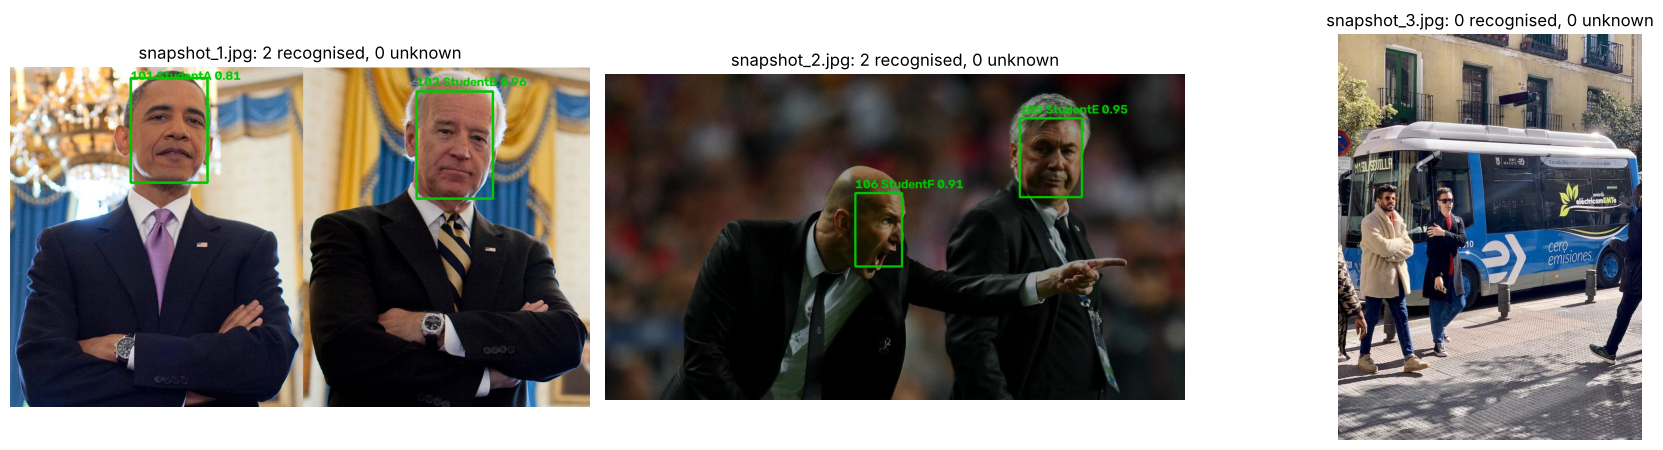

In [6]:
def run_session(con, frames, course="Computer Vision"):
    roll_nos, gallery = load_gallery(con)
    started = datetime.datetime.now()
    sid = con.execute("INSERT INTO sessions(course, started_at) VALUES (?, ?)",
                      (course, started.isoformat(timespec="seconds"))).lastrowid
    seen = {}                                                    # roll_no -> (first_seen, best score)
    shown = []
    for label, frame in frames:
        results = recognise_frame(frame, roll_nos, gallery)
        for face, roll, score in results:
            if roll != "unknown":
                first = seen.get(roll, (datetime.datetime.now().strftime("%H:%M:%S"), 0))[0]
                seen[roll] = (first, max(score, seen.get(roll, (None, 0))[1]))
        shown.append((label, draw(frame, results), results))
    for roll, name in con.execute("SELECT roll_no, name FROM students ORDER BY roll_no").fetchall():
        status = "Present" if roll in seen else "Absent"
        first, score = seen.get(roll, ("", 0.0))
        con.execute("INSERT OR REPLACE INTO attendance VALUES (?, ?, ?, ?, ?)", (sid, roll, status, first, round(score, 3)))
    con.commit()
    return sid, shown

def frames_from_folder(folder):
    for path in sorted(glob.glob(os.path.join(folder, "*"))):
        if path.lower().endswith((".jpg", ".jpeg", ".png")):
            yield os.path.basename(path), cv2.imread(path)
        elif path.lower().endswith((".mp4", ".avi", ".mov")):            # a short classroom video: sample ~2 frames/s
            cap = cv2.VideoCapture(path); fps = cap.get(cv2.CAP_PROP_FPS) or 25; k = 0
            while True:
                ok, frame = cap.read()
                if not ok:
                    break
                if k % int(fps // 2 or 1) == 0:
                    yield f"{os.path.basename(path)}@{k}", frame
                k += 1
            cap.release()

session_id, shown = run_session(con, frames_from_folder(os.path.join(DATA, "class")))
fig, ax = plt.subplots(1, len(shown), figsize=(6 * len(shown), 4.6))
for a, (label, img, res) in zip(np.atleast_1d(ax), shown):
    a.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); a.axis("off")
    a.set_title(f"{label}: {sum(r[1] != 'unknown' for r in res)} recognised, {sum(r[1] == 'unknown' for r in res)} unknown")
plt.tight_layout(); plt.show()

**Webcam version** (run on your laptop; press `q` to finish). The camera scans for `SCAN_SECONDS` while students look up, and every frame adds to the same session.

In [7]:
RUN_WEBCAM = False
SCAN_SECONDS = 20

def webcam_frames(seconds=SCAN_SECONDS, camera=0):
    cap = cv2.VideoCapture(camera); end = datetime.datetime.now() + datetime.timedelta(seconds=seconds)
    while datetime.datetime.now() < end:
        ok, frame = cap.read()
        if not ok:
            break
        cv2.imshow("Attendance scan - press q to stop", frame)
        if cv2.waitKey(1) & 0xFF == ord("q"):
            break
        yield "webcam", frame
    cap.release(); cv2.destroyAllWindows()

if RUN_WEBCAM:
    session_id, shown = run_session(con, webcam_frames())
else:
    print("Webcam scan skipped. Set RUN_WEBCAM = True on your laptop.")

Webcam scan skipped. Set RUN_WEBCAM = True on your laptop.


## 5 · The attendance sheet: generated automatically

In [8]:
sheet = pd.read_sql('''
    SELECT s.started_at AS date_time, s.course, a.roll_no, st.name, a.status, a.first_seen, a.score
    FROM attendance a JOIN sessions s ON s.id = a.session_id JOIN students st ON st.roll_no = a.roll_no
    WHERE a.session_id = ? ORDER BY a.roll_no''', con, params=(session_id,))
csv_path = f"attendance_logs/attendance_session{session_id}_{datetime.date.today()}.csv"
sheet.to_csv(csv_path, index=False)
print(sheet.to_string(index=False))
print(f"\nPresent: {(sheet.status == 'Present').sum()} / {len(sheet)}   ->  saved {csv_path} (and the database {DB_PATH})")

          date_time          course roll_no     name  status first_seen  score
2026-10-22T10:47:53 Computer Vision     101 StudentA Present   10:47:53  0.807
2026-10-22T10:47:53 Computer Vision     102 StudentB Present   10:47:53  0.964
2026-10-22T10:47:53 Computer Vision     103 StudentC  Absent             0.000
2026-10-22T10:47:53 Computer Vision     104 StudentD  Absent             0.000
2026-10-22T10:47:53 Computer Vision     105 StudentE Present   10:47:53  0.951
2026-10-22T10:47:53 Computer Vision     106 StudentF Present   10:47:53  0.906

Present: 4 / 6   ->  saved attendance_logs/attendance_session1_2026-10-22.csv (and the database demo_attendance.db)


## 6 · Evaluation: accuracy and limitations

Write the roll numbers of the students who were **really** present into `present.txt` (one per line) and compare:

| | Marked present | Marked absent |
|---|---|---|
| **Really present** | ✅ true positive | ❌ **missed student** (false negative) |
| **Really absent** | ❌ **false attendance** (false positive), the serious one (proxy or look-alike) | ✅ true negative |

- **Accuracy** = correctly marked students / all students.
- **Precision** = of those marked present, how many really were there.
- **Recall** = of those really there, how many were marked.

In [9]:
truth_file = os.path.join(DATA, "class", "present.txt")
if os.path.exists(truth_file):
    truly_present = {line.strip() for line in open(truth_file) if line.strip()}
    sheet["really_present"] = sheet.roll_no.isin(truly_present)
    sheet["marked_present"] = sheet.status == "Present"
    tp = int((sheet.really_present & sheet.marked_present).sum())
    fp = int((~sheet.really_present & sheet.marked_present).sum())
    fn = int((sheet.really_present & ~sheet.marked_present).sum())
    tn = int((~sheet.really_present & ~sheet.marked_present).sum())
    print(f"true positives {tp} | false attendance (FP) {fp} | missed students (FN) {fn} | true negatives {tn}")
    print(f"accuracy {(tp + tn) / len(sheet):.0%} | precision {tp / max(tp + fp, 1):.0%} | recall {tp / max(tp + fn, 1):.0%}")
    print(sheet[["roll_no", "name", "status", "score", "really_present"]].to_string(index=False))
else:
    print("Create", truth_file, "with the roll numbers that were really present to evaluate.")

true positives 4 | false attendance (FP) 0 | missed students (FN) 0 | true negatives 2
accuracy 100% | precision 100% | recall 100%
roll_no     name  status  score  really_present
    101 StudentA Present  0.807            True
    102 StudentB Present  0.964            True
    103 StudentC  Absent  0.000           False
    104 StudentD  Absent  0.000           False
    105 StudentE Present  0.951            True
    106 StudentF Present  0.906            True


In the demo, all four present students were found and the two absent ones were correctly marked absent. The street photo's faces were too small (under `min_face`) and were ignored rather than guessed. With a real class, test across **several lectures** and report the average, plus **where** mistakes happen (back rows, side angles, bad lighting).

## 7 · Limitations and improvements (for your report)
| Limitation | Effect | Improvement |
|---|---|---|
| **Small or distant faces** at the back of the room | missed students | higher-resolution camera, several snapshots, a second camera, ask students to look up for a few seconds |
| **Occlusion** (heads blocking heads, hands, masks) | missed students | multiple frames over 10–30 s; keep each student's best score |
| **Lighting** (window glare, dim rooms) | lower scores | register photos in similar lighting; histogram equalization / CLAHE (Week 1 Day 4) |
| **Pose** (looking down at notes) | missed or wrong matches | register slightly turned photos too; use video and keep the best frame |
| **Look-alikes / twins** | false attendance | raise the threshold; require the match in several frames |
| **Proxy attendance with a photo** of an absent friend | false attendance | liveness checks (blinks, movement across frames), teacher spot-checks |
| **Privacy and consent** | legal and ethical risk | store embeddings not photos, get consent, restrict access, delete at end of term |

**Report outline:** objective → setup (camera, models, database schema) → dataset (10+ students, photos each, number of sessions) → method (pipeline + matching rules) → results (accuracy/precision/recall per session, example mistakes) → limitations and improvements.